<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 1 · Sesión 3: Segmentación, concentración, crecimiento, alertas tempranas y cobranza</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: HHI, plan de crecimiento, SAT y watchlist, priorización de cobranza, curación y refinanciamiento</div>
</div>

## Objetivos de la sesión (2 horas)

1. Segmentar clientes, productos y portafolios, y leer riesgo y crecimiento en una misma matriz.
2. Medir **concentración** (HHI, participación de los mayores) y evaluar la **diversificación** de la cartera.
3. **Planificar el crecimiento**: proyectar el efecto de un plan comercial sobre pérdida esperada y capital.
4. Construir un **sistema de alerta temprana** y una **lista de vigilancia** con datos de comportamiento.
5. Diseñar **estrategias de cobranza** con capacidad limitada y evaluar **refinanciamiento, reestructuración y curación**.

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 15 min | Segmentación de cartera |
| 2 | 15 min | Concentración y diversificación |
| 3 | 15 min | Planificación del crecimiento |
| 4 | 30 min | Alerta temprana y lista de vigilancia |
| 5 | 20 min | Estrategias de cobranza con capacidad limitada |
| 6 | 15 min | Curación, re-default y refinanciamiento |
| 7 | 10 min | Ejercicios |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
p = pd.read_csv(DATA / "cartera_panel_mensual.csv.gz")
vig = p[p.estado == "Vigente"]
CORTE = "2026-06"
foto = vig[vig.periodo == CORTE]
print(p.shape, "| créditos vigentes al corte:", len(foto))

(286560, 17) | créditos vigentes al corte: 7904


## 1. Segmentación de cartera
Una buena segmentación cumple tres condiciones: **homogeneidad interna** (riesgo parecido dentro del segmento), **heterogeneidad entre segmentos** y **accionabilidad** (cada segmento recibe una estrategia distinta).

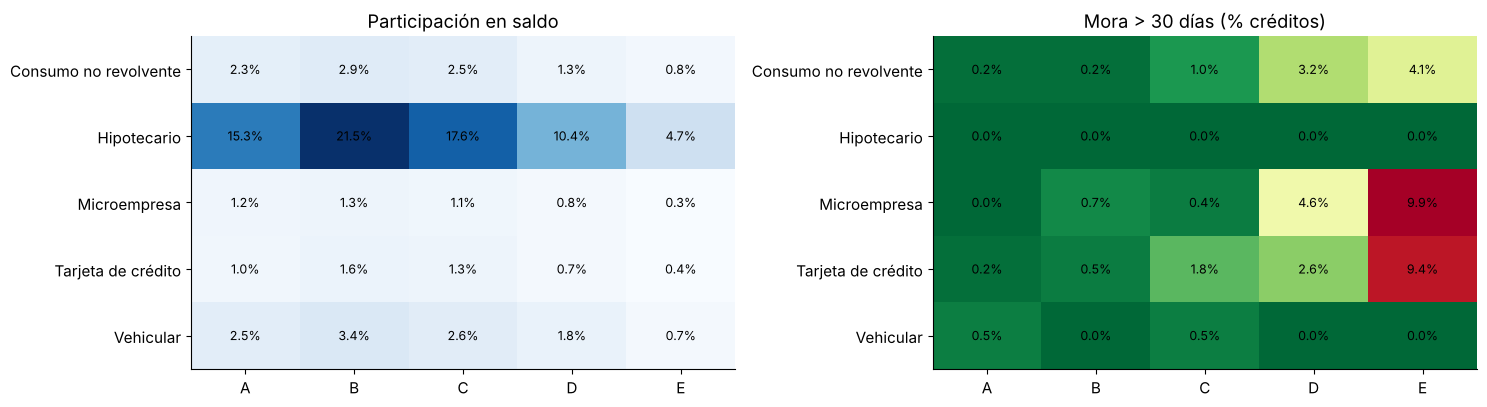

In [2]:
seg = foto.groupby(["producto", "segmento_riesgo"]).agg(saldo=("saldo", "sum"), mora=("dias_atraso", lambda s: (s > 30).mean()))
seg["part_saldo"] = seg.saldo / seg.saldo.sum()
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
for a, m, t, cmap in [(ax[0], seg.part_saldo.unstack(), "Participación en saldo", "Blues"), (ax[1], seg.mora.unstack(), "Mora > 30 días (% créditos)", "RdYlGn_r")]:
    a.imshow(m.values, cmap=cmap, aspect="auto")
    a.set_xticks(range(m.shape[1])); a.set_xticklabels(m.columns); a.set_yticks(range(m.shape[0])); a.set_yticklabels(m.index)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            a.text(j, i, f"{m.values[i, j]:.1%}", ha="center", va="center", fontsize=9)
    a.set_title(t); a.grid(False)
plt.tight_layout(); plt.show()

## 2. Concentración y diversificación
El **índice de Herfindahl-Hirschman** (HHI) suma los cuadrados de las participaciones: $HHI = \sum_k w_k^2$. Va de $1/K$ (perfectamente diversificado entre $K$ grupos) a 1 (todo en un grupo). Su inverso es el **número equivalente** de grupos de igual tamaño.

In [3]:
def hhi(s):
    w = s / s.sum()
    return pd.Series({"grupos": len(w), "HHI": (w ** 2).sum(), "n_equivalente": 1 / (w ** 2).sum(), "mayor_%": w.max()})
conc = pd.DataFrame({dim: hhi(foto.groupby(dim).saldo.sum()) for dim in ["producto", "region", "canal", "segmento_riesgo"]}).T
conc["deudores_top1%_%"] = np.nan
w = np.sort(foto.saldo.values)[::-1] / foto.saldo.sum()
print(f"Los mayores 1 % de deudores concentran {w[:int(len(w) * 0.01)].sum():.1%} del saldo; los mayores 10, {w[:10].sum():.2%}")
conc.drop(columns="deudores_top1%_%").style.format({"grupos": "{:.0f}", "HHI": "{:.3f}", "n_equivalente": "{:.1f}", "mayor_%": "{:.1%}"})

Los mayores 1 % de deudores concentran 12.6% del saldo; los mayores 10, 2.50%


,grupos,HHI,n_equivalente,mayor_%
producto,5,0.509,2.0,69.4%
region,5,0.337,3.0,51.6%
canal,4,0.312,3.2,44.9%
segmento_riesgo,5,0.234,4.3,30.7%


**Lectura:** en minorista la concentración **individual** es baja, pero la concentración **por producto** puede ser alta (el hipotecario domina el saldo) y la concentración **geográfica** (Lima Metropolitana) expone la cartera a shocks regionales. Los límites de concentración deben definirse por dimensión: producto, región, canal, convenio o empleador.

## 3. Planificación del crecimiento
Un plan comercial es también un plan de riesgo. Proyectemos tres planes sobre la cartera actual usando la **PD a 12 meses through-the-cycle** y la **LGD** por producto (estimadas en la sesión 2) y una aproximación del capital IRB.

In [4]:
from scipy.stats import norm
param = pd.DataFrame({  # PD TTC y LGD aproximadas de la sesión 2 (notebook M01_S02, sección 7)
    "PD": {"Tarjeta de crédito": .079, "Consumo no revolvente": .046, "Microempresa": .072, "Vehicular": .021, "Hipotecario": .008},
    "LGD": {"Tarjeta de crédito": .79, "Consumo no revolvente": .79, "Microempresa": .78, "Vehicular": .62, "Hipotecario": .64},
    "rho": {"Tarjeta de crédito": .04, "Consumo no revolvente": .056, "Microempresa": .04, "Vehicular": .092, "Hipotecario": .15}})
param["K"] = param.LGD * (norm.cdf((norm.ppf(param.PD) + np.sqrt(param.rho) * norm.ppf(.999)) / np.sqrt(1 - param.rho)) - param.PD)
saldo0 = foto.groupby("producto").saldo.sum()
planes = {"Actual": {}, "A: tarjeta +40 %": {"Tarjeta de crédito": .40},
          "B: consumo +25 %, micro +25 %": {"Consumo no revolvente": .25, "Microempresa": .25},
          "C: hipotecario +20 %": {"Hipotecario": .20}}
filas = []
for nombre, g in planes.items():
    s = saldo0 * pd.Series({k: 1 + g.get(k, 0) for k in saldo0.index})
    filas.append({"plan": nombre, "saldo_MM": s.sum() / 1e6, "crecimiento": s.sum() / saldo0.sum() - 1,
                  "EL_MM": (s * param.PD * param.LGD).sum() / 1e6, "capital_MM": (s * param.K).sum() / 1e6})
pl = pd.DataFrame(filas).set_index("plan")
pl["EL_%_saldo"] = pl.EL_MM / pl.saldo_MM; pl["capital_%_saldo"] = pl.capital_MM / pl.saldo_MM
pl.style.format({"saldo_MM": "{:,.1f}", "crecimiento": "{:.1%}", "EL_MM": "{:,.2f}", "capital_MM": "{:,.2f}", "EL_%_saldo": "{:.2%}", "capital_%_saldo": "{:.2%}"})

,saldo_MM,crecimiento,EL_MM,capital_MM,EL_%_saldo,capital_%_saldo
plan,,,,,,
Actual,305.8,0.0%,4.39,19.64,1.44%,6.42%
A: tarjeta +40 %,312.0,2.0%,4.78,20.27,1.53%,6.50%
"B: consumo +25 %, micro +25 %",316.8,3.6%,4.86,20.67,1.53%,6.52%
C: hipotecario +20 %,348.2,13.9%,4.61,21.98,1.32%,6.31%


**Mensaje clave:** el plan A crece menos en saldo que el plan C, pero aumenta mucho más la pérdida esperada (y las provisiones). El crecimiento debe evaluarse por **mezcla de producto**, no sólo por volumen: el mismo +5 % de cartera puede tener costos de riesgo y de capital muy distintos.

## 4. Sistema de alerta temprana (SAT) y lista de vigilancia
Objetivo: identificar **hoy**, entre los clientes **al día**, quiénes tienen alta probabilidad de caer en **30+ días en los próximos 3 meses**, para actuar antes (contacto preventivo, reducción de línea, reestructuración temprana).

Variables de comportamiento (ventana de 6 meses): meses con atraso, atraso máximo, amortización del saldo, antigüedad (MOB), producto, segmento y el índice macro.

In [5]:
pv = p[p.estado == "Vigente"].sort_values(["id_credito", "periodo"]).copy()
g = pv.groupby("id_credito")
pv["atr_max_6m"] = g.dias_atraso.transform(lambda s: s.rolling(6, min_periods=1).max())
pv["meses_atr_6m"] = g.dias_atraso.transform(lambda s: (s > 0).rolling(6, min_periods=1).sum())
pv["amortizacion"] = 1 - pv.saldo / pv.monto_desembolsado
# variable objetivo: 30+ días en alguno de los próximos 3 meses
fut = [g.dias_atraso.shift(-k) for k in (1, 2, 3)]
pv["malo_3m"] = (pd.concat(fut, axis=1).max(axis=1) > 30).astype(float)
pv.loc[pd.concat(fut, axis=1).isna().all(axis=1), "malo_3m"] = np.nan
macro = pd.read_csv(DATA / "macro_peru_ilustrativa.csv").set_index("periodo").indice_estres_simulado
pv["estres"] = pv.periodo.map(macro)
base = pv[(pv.dias_atraso == 0) & pv.malo_3m.notna() & (pv.periodo >= "2023-01")].copy()
X = pd.get_dummies(base[["atr_max_6m", "meses_atr_6m", "amortizacion", "mob", "estres", "producto", "segmento_riesgo"]], drop_first=True).astype(float)
dev, oot = base.periodo <= "2025-06", base.periodo > "2025-06"          # desarrollo y fuera de tiempo
sat = LogisticRegression(max_iter=3000).fit(X[dev], base.malo_3m[dev])
base["score_sat"] = sat.predict_proba(X)[:, 1]
print(f"Tasa de evento: {base.malo_3m.mean():.2%} | AUC desarrollo {roc_auc_score(base.malo_3m[dev], base.score_sat[dev]):.3f} | AUC fuera de tiempo {roc_auc_score(base.malo_3m[oot], base.score_sat[oot]):.3f}")

Tasa de evento: 1.16% | AUC desarrollo 0.823 | AUC fuera de tiempo 0.819


In [6]:
o = base[oot].copy()
o["decil"] = pd.qcut(o.score_sat.rank(method="first"), 10, labels=range(10, 0, -1))   # 1 = mayor riesgo
t = o.groupby("decil", observed=True).agg(clientes=("malo_3m", "size"), eventos=("malo_3m", "sum"), tasa=("malo_3m", "mean")).sort_index(ascending=False)
t["captura_acum"] = t.eventos.cumsum() / t.eventos.sum()
t["lift"] = t.tasa / o.malo_3m.mean()
display(t.style.format({"eventos": "{:.0f}", "tasa": "{:.2%}", "captura_acum": "{:.1%}", "lift": "{:.1f}x"}))
print(f"Lista de vigilancia (decil 1): {t.iloc[0].clientes:.0f} clientes-mes, captura el {t.iloc[0].captura_acum:.0%} de las futuras moras con un lift de {t.iloc[0].lift:.1f}x")

,clientes,eventos,tasa,captura_acum,lift
decil,,,,,
1,9778,260,2.66%,49.8%,5.0x
2,9777,78,0.80%,64.8%,1.5x
3,9778,67,0.69%,77.6%,1.3x
4,9777,50,0.51%,87.2%,1.0x
5,9777,25,0.26%,92.0%,0.5x
6,9778,20,0.20%,95.8%,0.4x
7,9777,4,0.04%,96.6%,0.1x
8,9778,11,0.11%,98.7%,0.2x
9,9777,5,0.05%,99.6%,0.1x


Lista de vigilancia (decil 1): 9778 clientes-mes, captura el 50% de las futuras moras con un lift de 5.0x


**Lista de vigilancia (watchlist):** los clientes del decil más riesgoso entran a una lista con reglas explícitas de **entrada** (score > umbral, alerta de buró, sobreendeudamiento), **acciones** (contacto preventivo, congelar incrementos de línea, oferta de reestructuración) y **salida** (3 meses sin alertas). La lista se revisa en comité y su efectividad se mide por la reducción de entradas a mora frente a un grupo de control.

## 5. Estrategias de cobranza con capacidad limitada
El call center tiene capacidad para gestionar solo una parte de los clientes en mora temprana (1-30 días). Estimamos la **probabilidad de cura sin gestión** y priorizamos donde la gestión agrega más valor esperado.

In [7]:
pv["cura_1m"] = (g.dias_atraso.shift(-1) == 0).astype(float)
mt = pv[(pv.bucket_atraso == "1-30") & pv.groupby("id_credito").dias_atraso.shift(-1).notna() & (pv.periodo >= "2023-01")].copy()
Xc = pd.get_dummies(mt[["meses_atr_6m", "amortizacion", "mob", "estres", "producto", "segmento_riesgo"]], drop_first=True).astype(float)
cura = LogisticRegression(max_iter=3000).fit(Xc, mt.cura_1m)
mt["p_cura"] = cura.predict_proba(Xc)[:, 1]
print(f"Tasa de cura promedio 1-30 → 0: {mt.cura_1m.mean():.1%} | AUC del score de cura: {roc_auc_score(mt.cura_1m, mt.p_cura):.3f}")

# Supuesto de efecto de la gestión: la llamada aumenta la probabilidad de cura en 30 % relativo de lo que falta para curar
UPLIFT, CAPACIDAD = 0.30, 0.25                          # se puede llamar al 25 % de los clientes del mes
mes = mt[mt.periodo == "2026-05"].copy()
mes["valor_gestion"] = UPLIFT * (1 - mes.p_cura) * mes.saldo        # saldo que se espera "salvar" de rodar
estrategias = {
    "Aleatoria": mes.sample(frac=CAPACIDAD, random_state=1).index,
    "Mayor saldo": mes.nlargest(int(len(mes) * CAPACIDAD), "saldo").index,
    "Menor p(cura)": mes.nsmallest(int(len(mes) * CAPACIDAD), "p_cura").index,
    "Mayor valor esperado": mes.nlargest(int(len(mes) * CAPACIDAD), "valor_gestion").index,
}
pd.Series({k: mes.loc[v, "valor_gestion"].sum() for k, v in estrategias.items()}, name="saldo esperado salvado (S/)").to_frame().style.format("{:,.0f}")

Tasa de cura promedio 1-30 → 0: 48.7% | AUC del score de cura: 0.646


,saldo esperado salvado (S/)
Aleatoria,"54,331"
Mayor saldo,"163,401"
Menor p(cura),"60,863"
Mayor valor esperado,"165,907"


**Mensaje clave:** priorizar por **valor esperado** (probabilidad de no curar × efecto de la gestión × saldo) supera a las reglas simples. En la práctica el "efecto de la gestión" (*uplift*) debe medirse con **grupos de control aleatorios**, no suponerse.

### Matriz de estrategias de cobranza temprana

| | Saldo bajo | Saldo alto |
|---|---|---|
| **p(cura) alta** | Recordatorio digital (SMS, WhatsApp, app) | Recordatorio digital + llamada |
| **p(cura) baja** | Call center, ofrecer fecha de pago | Gestor dedicado, evaluar refinanciamiento |

## 6. Curación, re-default y refinanciamiento
- **Curación:** el cliente regresa a estar al día. No es lo mismo que "riesgo resuelto": hay que medir el **re-default**.
- **Refinanciamiento:** cambia las condiciones (plazo, cuota) por dificultades de pago. **Reestructuración:** cambio más profundo, a menudo bajo un proceso formal. Para la SBS ambos tienen tratamiento de clasificación y provisiones específico.

In [8]:
pr = p[p.estado != "Cancelado"].sort_values(["id_credito", "periodo"])
ev = []
for cid, d in pr.groupby("id_credito"):
    b = d.bucket_atraso.values; per = d.periodo.values
    idx = np.where(b == "31-60")[0]
    if len(idx) == 0: continue
    i0 = idx[0]
    sig = b[i0 + 1:i0 + 7]
    curo = "0" in sig
    redefault = np.nan
    if curo:
        j = i0 + 1 + list(sig).index("0")
        redefault = float(any(x not in ("0", "1-30") for x in b[j + 1:j + 13])) if len(b) > j + 12 else np.nan
    ev.append((d.producto.iloc[0], curo, redefault))
ev = pd.DataFrame(ev, columns=["producto", "curo_6m", "redefault_12m"])
ev.groupby("producto").agg(casos=("curo_6m", "size"), tasa_cura_6m=("curo_6m", "mean"), re_default_12m=("redefault_12m", "mean")).style.format({"tasa_cura_6m": "{:.1%}", "re_default_12m": "{:.1%}"})

,casos,tasa_cura_6m,re_default_12m
producto,,,
Consumo no revolvente,496,31.9%,15.1%
Hipotecario,31,45.2%,0.0%
Microempresa,398,26.4%,55.6%
Tarjeta de crédito,875,32.7%,14.9%
Vehicular,61,37.7%,15.0%


In [9]:
# ¿Conviene refinanciar? Valor esperado por cada S/ 100 de saldo en 61-90 días (supuestos ilustrativos, discutir en clase)
def valor_esperado(p_cura, lgd, costo=0.0, perdida_margen=0.0):
    return 100 * (p_cura * (1 - perdida_margen) + (1 - p_cura) * (1 - lgd)) - 100 * costo
sin = valor_esperado(p_cura=0.12, lgd=0.78)
con = valor_esperado(p_cura=0.45, lgd=0.78, costo=0.03, perdida_margen=0.10)
print(f"Sin refinanciar: S/ {sin:.1f} recuperados por cada S/ 100 | Con refinanciamiento: S/ {con:.1f}")
p_eq = [x for x in np.linspace(0.12, 0.6, 200) if valor_esperado(x, 0.78, 0.03, 0.10) >= sin][0]
print(f"El refinanciamiento conviene si eleva la probabilidad de cura por encima de {p_eq:.0%}")

Sin refinanciar: S/ 31.4 recuperados por cada S/ 100 | Con refinanciamiento: S/ 49.6
El refinanciamiento conviene si eleva la probabilidad de cura por encima de 18%


**Gobierno del refinanciamiento:** si no se controla, el refinanciamiento **oculta mora** (el crédito vuelve a estar "al día" sin capacidad real de pago). Buenas prácticas: criterios de elegibilidad, análisis de capacidad de pago, marca de refinanciado en los sistemas, seguimiento del re-default por cosecha de refinanciamiento y clasificación/provisión según la normativa.

## 7. Ejercicios
1. Agrega al SAT la variable "uso de línea" para tarjeta (proxy: saldo / monto). ¿Mejora el AUC fuera de tiempo?
2. Repite la priorización de cobranza con capacidad de 10 % y de 50 %. ¿Cómo cambia la ganancia de la estrategia por valor esperado?
3. Propón límites de concentración por región y producto para el comité.
4. ¿Qué re-default máximo tolerarías para seguir refinanciando microempresa?